##### Feladat (Példatár 4.4)

Egy $d = 20 ~\mathrm{mm}$ átmérőjű acél tengelyt az $A$ és $D$ csapágyak támasztják meg, melyek engedik a tengely kisméretű szögelfordulását. Az $A$ csapágy gátolja a tengelyirányú elmozdulást, míg a $D$ csapágy engedélyezi. A tengely terhelése a $B$ és $C$ szíjtárcsákról átadódó erők és nyomatékok. Határozzuk meg a tengelyben ébredő maximális Mohr és HMH féle egyenértékű feszültségeket! Mekkora legyen a tengely átmérője, ha $\sigma_\mathrm{meg} = 300 ~\mathrm{MPa}$?

Adatok: $d = 20 ~\mathrm{mm}$, $L_1 = 150 ~\mathrm{mm}$, $L_2 = 300 ~\mathrm{mm}$, $L_3 = 150 ~\mathrm{mm}$, $\sigma_\mathrm{meg} = 300 ~\mathrm{MPa}$, a $B$ szíjtárcsán $F_{B1} = 2100 ~\mathrm{N}$ és $F_{B2} = 300 ~\mathrm{N}$ szíjerő, $r_B = 60 ~\mathrm{mm}$ sugár, a $C$ szíjtárcsán $F_{C1} = 1100 ~\mathrm{N}$ és $F_{C2} = 200 ~\mathrm{N}$ szíjerő, $r_C = 120 ~\mathrm{mm}$ sugár.

Feladatok:

a) Mekkora a tengelyben ébredő maximális Mohr és HMH féle egyenértékű feszültség ($\sigma_\mathrm{egy}^\mathrm{Mohr}$, $\sigma_\mathrm{egy}^\mathrm{HMH}$)?

b) Mekkora legyen a tengely $d$ átmérője, ha $\sigma_\mathrm{meg} = 300 ~\mathrm{MPa}$?

<img src="img/01.jpg" alt="Feladat" width=600px>

##### Csomagok importálása

In [1]:
import numpy as np # Numerikus számítások
import matplotlib.pyplot as plt # Ábrázolás
plt.rcParams['mathtext.fontset'] = 'cm' # Betűtípus az ábrákon
plt.rcParams['font.family'] = 'serif' # Betűtípus az ábrákon
plt.rcParams['font.serif'] = ['cmr10'] # Betűtípus az ábrákon
plt.rcParams['axes.formatter.use_mathtext'] = True # Betűtípus az ábrákon
plt.rcParams['axes.unicode_minus'] = False # Betűtípus az ábrákon
from IPython.display import display, Math, Latex # Szép kimenet Jupyter notebookban
import sympy as sp # Szimbólikus számítások
from sympy import latex # Szép kimenet Jupyter notebookban
sp.init_printing() # Szép kimenet Jupyter notebookban

##### Adatok

In [2]:
d_data = 20 # mm
L_1_data = 150 # mm
L_2_data = 300 # mm
L_3_data = 150 # mm
F_B1_data = 2100 # N
F_B2_data = 300 # N
r_B_data = 60 # mm
F_C1_data = 1100 # N
F_C2_data = 200 # N
r_C_data = 120 # mm
sigma_meg_data = 300 # MPa

# Az adatok már N, mm, MPa rendszerben vannak

In [3]:
d, L_1, L_2, L_3, sigma_meg = sp.symbols('d, L_1, L_2, L_3, sigma_meg', positive=True)
F_B1, F_B2, r_B, F_C1, F_C2, r_C = sp.symbols('F_B1, F_B2, r_B, F_C1, F_C2, r_C', positive=True)
x = sp.Symbol('x')

In [4]:
data = [(d, d_data),
        (L_1, L_1_data),
        (L_2, L_2_data),
        (L_3, L_3_data),
        (F_B1, F_B1_data),
        (F_B2, F_B2_data),
        (r_B, r_B_data),
        (F_C1, F_C1_data),
        (F_C2, F_C2_data),
        (r_C, r_C_data),
        (sigma_meg, sigma_meg_data)]

#### a) A maximális Mohr és HMH féle egyenértékű feszültség

##### Szíjtárcsákról átadódó terhelések

A szíjerőket a tengely középvonalába redukáljuk. A két szíjerő összege a tengelyt hajlító erő, a két szíjerő különbségének és a tárcsa sugarának szorzata pedig a tengelyt csavaró nyomaték.

In [5]:
# B szíjtárcsa
F_B = (F_B1 + F_B2).subs(data)
display(Math(rf'F_B = F_{{B1}} + F_{{B2}} = {latex(F_B1.subs(data))} + {latex(F_B2.subs(data))} = {latex(F_B)} ~\mathrm{{N}}'))

M_B = ((F_B1 - F_B2) * r_B).subs(data)
display(Math(rf'M_B = \left( F_{{B1}} - F_{{B2}} \right) \cdot r_B = \left( {latex(F_B1.subs(data))} - {latex(F_B2.subs(data))} \right) \cdot {latex(r_B.subs(data))} = {latex(M_B)} ~\mathrm{{Nmm}}'))

# C szíjtárcsa
F_C = (F_C1 + F_C2).subs(data)
display(Math(rf'F_C = F_{{C1}} + F_{{C2}} = {latex(F_C1.subs(data))} + {latex(F_C2.subs(data))} = {latex(F_C)} ~\mathrm{{N}}'))

M_C = ((F_C1 - F_C2) * r_C).subs(data)
display(Math(rf'M_C = \left( F_{{C1}} - F_{{C2}} \right) \cdot r_C = \left( {latex(F_C1.subs(data))} - {latex(F_C2.subs(data))} \right) \cdot {latex(r_C.subs(data))} = {latex(M_C)} ~\mathrm{{Nmm}}'))

<IPython.core.display.Math object>

<IPython.core.display.Math object>

<IPython.core.display.Math object>

<IPython.core.display.Math object>

##### Reakcióerők

<img src="img/02.jpg" alt="Feladat" width=600px>

In [6]:
F_A, F_D = sp.symbols('F_A, F_D') # Ismeretlen reakcióerők

# z irányú erő egyensúly
eq1 = F_A - F_B - F_C + F_D
display(Math(rf'\sum F_z = 0 \quad \longrightarrow \quad F_A - {latex(F_B)} - {latex(F_C)} + F_D = 0'))

# A pontra számított nyomatéki egyensúly
eq2 = (-F_B*L_1 - F_C*(L_1 + L_2) + F_D*(L_1 + L_2 + L_3)).subs(data)
display(Math(rf'\sum M_A = 0 \quad \longrightarrow \quad -{latex(F_B)} \cdot {latex(L_1.subs(data))} - {latex(F_C)} \cdot {latex((L_1 + L_2).subs(data))} + F_D \cdot {latex((L_1 + L_2 + L_3).subs(data))} = 0'))

# x tengely körüli nyomatéki egyensúly (a csavarónyomatékok egyensúlyban vannak)
eq3 = -M_B + M_C
display(Math(rf'\sum M_x = 0 \quad \longrightarrow \quad -M_B + M_C = -{latex(M_B)} + {latex(M_C)} = {latex(eq3)}'))

<IPython.core.display.Math object>

<IPython.core.display.Math object>

<IPython.core.display.Math object>

In [7]:
# Rendszer megoldása
sol = sp.solve([eq1, eq2], [F_A, F_D])

F_A_sol = sol[F_A]
display(Math(rf'F_A = {latex(F_A_sol)} ~\mathrm{{N}}'))

F_D_sol = sol[F_D]
display(Math(rf'F_D = {latex(F_D_sol)} ~\mathrm{{N}}'))

<IPython.core.display.Math object>

<IPython.core.display.Math object>

##### Igénybevételek

Az $x$ tengely az $A$ pontból indul és jobbra mutat. Az I. szakasz az $AB$ ($x \in [0, L_1]$), a II. szakasz a $BC$ ($x \in [L_1, L_1 + L_2]$), a III. szakasz a $CD$ ($x \in [L_1 + L_2, L_1 + L_2 + L_3]$) szakasz. Az igénybevételeket az $A$ pont felőli oldalról írjuk fel (az $x$ koordináta $\mathrm{mm}$-ben, a $V$ nyíróerő $\mathrm{N}$-ban, az $M_h$ hajlító- és $M_t$ csavarónyomaték $\mathrm{Nmm}$-ben adott).

In [8]:
# Szakaszhatárok
x_B = L_1.subs(data)
x_C = (L_1 + L_2).subs(data)
x_D = (L_1 + L_2 + L_3).subs(data)

# I. szakasz: x ∈ [0, L_1]
V_1 = F_A_sol
Mh_1 = F_A_sol * x
Mt_1 = 0
display(Latex('I. szakasz:'))
display(Math(rf'V_1(x) = F_A = {latex(V_1)}'))
display(Math(rf'M_{{h1}}(x) = F_A \cdot x = {latex(Mh_1)}'))
display(Math(rf'M_{{t1}}(x) = {latex(Mt_1)}'))

# II. szakasz: x ∈ [L_1, L_1 + L_2]
V_2 = F_A_sol - F_B
Mh_2 = sp.expand(F_A_sol * x - F_B * (x - x_B))
Mt_2 = M_B
display(Latex('II. szakasz:'))
display(Math(rf'V_2(x) = F_A - F_B = {latex(V_2)}'))
display(Math(rf'M_{{h2}}(x) = F_A \cdot x - F_B \cdot (x - L_1) = {latex(Mh_2)}'))
display(Math(rf'M_{{t2}}(x) = M_B = {latex(Mt_2)}'))

# III. szakasz: x ∈ [L_1 + L_2, L_1 + L_2 + L_3]
V_3 = F_A_sol - F_B - F_C
Mh_3 = sp.expand(F_A_sol * x - F_B * (x - x_B) - F_C * (x - x_C))
Mt_3 = M_B - M_C
display(Latex('III. szakasz:'))
display(Math(rf'V_3(x) = F_A - F_B - F_C = {latex(V_3)}'))
display(Math(rf'M_{{h3}}(x) = F_A \cdot x - F_B \cdot (x - L_1) - F_C \cdot (x - L_1 - L_2) = {latex(Mh_3)}'))
display(Math(rf'M_{{t3}}(x) = M_B - M_C = {latex(Mt_3)}'))

<IPython.core.display.Latex object>

<IPython.core.display.Math object>

<IPython.core.display.Math object>

<IPython.core.display.Math object>

<IPython.core.display.Latex object>

<IPython.core.display.Math object>

... (2 outputs left out)

<IPython.core.display.Latex object>

<IPython.core.display.Math object>

<IPython.core.display.Math object>

<IPython.core.display.Math object>

##### Ábrázolás

<img src="img/03.jpg" alt="Feladat" width=450px>

In [9]:
# Numerikus függvények
Mh_1_num = sp.lambdify(x, Mh_1, modules='numpy')
Mh_2_num = sp.lambdify(x, Mh_2, modules='numpy')
Mh_3_num = sp.lambdify(x, Mh_3, modules='numpy')

# x értékek
x_1_vals = np.linspace(0, float(x_B))
x_2_vals = np.linspace(float(x_B), float(x_C))
x_3_vals = np.linspace(float(x_C), float(x_D))
x_vals = np.concatenate((x_1_vals, x_2_vals, x_3_vals))

# y értékek (a nyíróerő és a csavarónyomaték szakaszonként konstans)
V_vals = np.concatenate((np.full_like(x_1_vals, float(V_1)),
                         np.full_like(x_2_vals, float(V_2)),
                         np.full_like(x_3_vals, float(V_3))))
Mh_vals = np.concatenate((Mh_1_num(x_1_vals),
                          Mh_2_num(x_2_vals),
                          Mh_3_num(x_3_vals)))
Mt_vals = np.concatenate((np.full_like(x_1_vals, float(Mt_1)),
                          np.full_like(x_2_vals, float(Mt_2)),
                          np.full_like(x_3_vals, float(Mt_3))))

# Nevezetes pontok
Mh_B_num = float(Mh_1.subs(x, x_B))
Mh_C_num = float(Mh_2.subs(x, x_C))

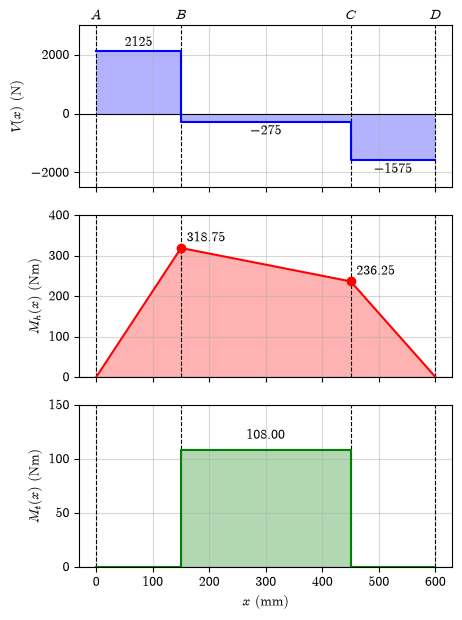

In [10]:
# Ábrázolás
fig, (ax_V, ax_Mh, ax_Mt) = plt.subplots(3, 1, figsize=(12/2.54, 16/2.54), sharex=True)

# Nyíróerő
ax_V.plot(x_vals, V_vals, color='blue', zorder=5)
ax_V.fill_between(x_vals, V_vals, 0, color='blue', alpha=0.3, linewidth=0)
ax_V.text(float(x_B) / 2, float(V_1) + 150, rf'${latex(V_1)}$', ha='center')
ax_V.text((float(x_B) + float(x_C)) / 2, float(V_2) - 450, rf'${latex(V_2)}$', ha='center')
ax_V.text((float(x_C) + float(x_D)) / 2, float(V_3) - 450, rf'${latex(V_3)}$', ha='center')
ax_V.axhline(0, color='black', linewidth=0.8)
ax_V.set_ylabel(r'$V(x) ~ \mathrm{(N)}$')
ax_V.grid(True, alpha=0.5)
ax_V.set_ylim(-2500, 3000)

# Hajlítónyomaték
ax_Mh.plot(x_vals, Mh_vals*1e-3, color='red', zorder=5)
ax_Mh.fill_between(x_vals, Mh_vals*1e-3, 0, color='red', alpha=0.3, linewidth=0)
ax_Mh.scatter([float(x_B), float(x_C)], [Mh_B_num*1e-3, Mh_C_num*1e-3], color='red', zorder=6)
ax_Mh.text(float(x_B) + 10, Mh_B_num*1e-3 + 15, rf'${Mh_B_num*1e-3:.2f}$', ha='left')
ax_Mh.text(float(x_C) + 10, Mh_C_num*1e-3 + 15, rf'${Mh_C_num*1e-3:.2f}$', ha='left')
ax_Mh.axhline(0, color='black', linewidth=0.8)
ax_Mh.set_ylabel(r'$M_h(x) ~ \mathrm{(Nm)}$')
ax_Mh.grid(True, alpha=0.5)
ax_Mh.set_ylim(0, 400)

# Csavarónyomaték
ax_Mt.plot(x_vals, Mt_vals*1e-3, color='green', zorder=5)
ax_Mt.fill_between(x_vals, Mt_vals*1e-3, 0, color='green', alpha=0.3, linewidth=0)
ax_Mt.text((float(x_B) + float(x_C)) / 2, float(Mt_2)*1e-3 + 10, rf'${float(Mt_2)*1e-3:.2f}$', ha='center')
ax_Mt.axhline(0, color='black', linewidth=0.8)
ax_Mt.set_xlabel(r'$x ~ \mathrm{(mm)}$')
ax_Mt.set_ylabel(r'$M_t(x) ~ \mathrm{(Nm)}$')
ax_Mt.grid(True, alpha=0.5)
ax_Mt.set_ylim(0, 150)

# Keresztmetszetek jelölése
for ax in (ax_V, ax_Mh, ax_Mt):
    for x_p in (0, x_B, x_C, x_D):
        ax.axvline(float(x_p), color='black', linestyle='--', linewidth=0.8)
for x_p, nev in zip((0, x_B, x_C, x_D), ('A', 'B', 'C', 'D')):
    ax_V.text(float(x_p), 3200, rf'${nev}$', ha='center')

plt.tight_layout()
plt.savefig('igenybeveteli_abrak.pdf')
plt.show()

##### Veszélyes keresztmetszet

A hajlítónyomaték a $B$ keresztmetszetben maximális, és itt a csavarónyomaték is működik (a $BC$ szakaszon állandó), így a veszélyes keresztmetszet a $B$ keresztmetszet.

In [11]:
# Igénybevételek a B keresztmetszetben
Mh_B = Mh_1.subs(x, x_B)
display(Math(rf'M_{{h,B}} = M_{{h1}}(L_1) = {latex(Mh_B)} ~\mathrm{{Nmm}}'))

Mt_B = Mt_2
display(Math(rf'M_{{t,B}} = M_{{t2}} = {latex(Mt_B)} ~\mathrm{{Nmm}}'))

<IPython.core.display.Math object>

<IPython.core.display.Math object>

##### Redukált nyomaték

Hajlítás és csavarás együttes működése esetén a kör keresztmetszet szélső szálában:

$$\sigma = \frac{M_h}{K_y}, \qquad \tau = \frac{M_t}{K_p}, \qquad \text{ahol} \quad K_p = 2 K_y$$

Az egyenértékű feszültségek:

$$\sigma_\mathrm{egy}^\mathrm{Mohr} = \sqrt{\sigma^2 + 4\tau^2} = \frac{\sqrt{M_h^2 + M_t^2}}{K_y}, \qquad \sigma_\mathrm{egy}^\mathrm{HMH} = \sqrt{\sigma^2 + 3\tau^2} = \frac{\sqrt{M_h^2 + 0.75 \cdot M_t^2}}{K_y}$$

Így a redukált nyomaték:

$$M_\mathrm{red} = \sqrt{M_h^2 + c \cdot M_t^2}, \qquad \text{ahol} \quad c = 1 ~ \text{(Mohr)}, \quad c = 0.75 ~ \text{(HMH)}$$

In [12]:
# Mohr elmélet
c_Mohr = 1
M_red_Mohr = sp.sqrt(Mh_B**2 + c_Mohr * Mt_B**2)
display(Math(rf'M_\mathrm{{red}}^\mathrm{{Mohr}} = \sqrt{{M_{{h,B}}^2 + M_{{t,B}}^2}} = \sqrt{{{latex(Mh_B)}^2 + {latex(Mt_B)}^2}} = {latex(round(M_red_Mohr, 1))} ~\mathrm{{Nmm}}'))

# HMH elmélet
c_HMH = 0.75
M_red_HMH = sp.sqrt(Mh_B**2 + c_HMH * Mt_B**2)
display(Math(rf'M_\mathrm{{red}}^\mathrm{{HMH}} = \sqrt{{M_{{h,B}}^2 + 0.75 \cdot M_{{t,B}}^2}} = \sqrt{{{latex(Mh_B)}^2 + 0.75 \cdot {latex(Mt_B)}^2}} = {latex(round(M_red_HMH, 1))} ~\mathrm{{Nmm}}'))

<IPython.core.display.Math object>

<IPython.core.display.Math object>

##### Keresztmetszeti tényező

In [13]:
K_y = d**3 * sp.pi / 32
display(Math(rf'K_y = \frac{{d^3 \pi}}{{32}} = {latex(round(K_y.subs(data), 3))} ~\mathrm{{mm^3}}'))

<IPython.core.display.Math object>

##### Egyenértékű feszültségek

In [14]:
# Mohr elmélet
sigma_egy_Mohr = M_red_Mohr / K_y.subs(data)
display(Math(rf'\sigma_\mathrm{{egy}}^\mathrm{{Mohr}} = \frac{{M_\mathrm{{red}}^\mathrm{{Mohr}}}}{{K_y}} = {latex(round(sigma_egy_Mohr, 2))} ~\mathrm{{MPa}}'))

# HMH elmélet
sigma_egy_HMH = M_red_HMH / K_y.subs(data)
display(Math(rf'\sigma_\mathrm{{egy}}^\mathrm{{HMH}} = \frac{{M_\mathrm{{red}}^\mathrm{{HMH}}}}{{K_y}} = {latex(round(sigma_egy_HMH, 2))} ~\mathrm{{MPa}}'))

<IPython.core.display.Math object>

<IPython.core.display.Math object>

In [15]:
# Megfelel-e a d = 20 mm átmérőjű tengely?
for nev, sigma_egy in (('Mohr', sigma_egy_Mohr), ('HMH', sigma_egy_HMH)):
    if sigma_egy > sigma_meg_data:
        display(Latex(rf'Mivel $\sigma_\mathrm{{egy}}^\mathrm{{{nev}}} = {round(sigma_egy, 2)} ~\mathrm{{MPa}} > \sigma_\mathrm{{meg}} = {sigma_meg_data} ~\mathrm{{MPa}}$, a tengely a {nev} elmélet szerint nem felel meg!'))
    else:
        display(Latex(rf'Mivel $\sigma_\mathrm{{egy}}^\mathrm{{{nev}}} = {round(sigma_egy, 2)} ~\mathrm{{MPa}} \leq \sigma_\mathrm{{meg}} = {sigma_meg_data} ~\mathrm{{MPa}}$, a tengely a {nev} elmélet szerint megfelel!'))

<IPython.core.display.Latex object>

<IPython.core.display.Latex object>

#### b) A tengely szükséges $d$ átmérője

A határhelyzetben az egyenértékű feszültség éppen a megengedett feszültséggel egyenlő:

$$\sigma_\mathrm{meg} = \frac{M_\mathrm{red}}{K_y} = \frac{M_\mathrm{red}}{\frac{d_\mathrm{min}^3 \pi}{32}} \quad \rightarrow \quad d_\mathrm{min} = \sqrt[3]{\frac{32 \cdot M_\mathrm{red}}{\sigma_\mathrm{meg} \cdot \pi}}$$

In [16]:
M_red = sp.Symbol('M_red', positive=True)

# Határhelyzet
eq = M_red / K_y - sigma_meg

# Rendszer megoldása
sol = sp.solve(eq, d)
d_min = sol[0]

# Mohr elmélet
d_min_Mohr = d_min.subs(M_red, M_red_Mohr).subs(data)
display(Math(rf'd_\mathrm{{min}}^\mathrm{{Mohr}} = \sqrt[3]{{\frac{{32 \cdot M_\mathrm{{red}}^\mathrm{{Mohr}}}}{{\sigma_\mathrm{{meg}} \cdot \pi}}}} = {latex(round(d_min_Mohr, 2))} ~\mathrm{{mm}}'))

# HMH elmélet
d_min_HMH = d_min.subs(M_red, M_red_HMH).subs(data)
display(Math(rf'd_\mathrm{{min}}^\mathrm{{HMH}} = \sqrt[3]{{\frac{{32 \cdot M_\mathrm{{red}}^\mathrm{{HMH}}}}{{\sigma_\mathrm{{meg}} \cdot \pi}}}} = {latex(round(d_min_HMH, 2))} ~\mathrm{{mm}}'))

<IPython.core.display.Math object>

<IPython.core.display.Math object>

A Mohr elmélet szerint nagyobb átmérő adódik, mint a HMH elmélet szerint, vagyis a Mohr elmélet szerinti méretezés a biztonság felé tér el! A tengely átmérője legyen legalább $d_\mathrm{min} \approx 22.52 ~\mathrm{mm}$.